# Predicting Malignancy in Single Cells

We start with a simple random forest to predict whether a cell is malignant or non-malignant.
We want the model to work on unseen melanoma patients, so we keep entire tumors out of training.

We use the processed melanoma data from [Tirosh et al. (GSE72056)](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE72056).
The labels are based on inferred copy-number changes. We use them as our reference labels.

# Get the Data

## Import the Required Libraries

In [1]:
from pathlib import Path
import pickle
from importlib.metadata import version

# Dataframes and single-cell data
import pandas as pd
import numpy as np
import scanpy as sc

# ML preparation and modeling
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

# Evaluation
from sklearn.metrics import (
    balanced_accuracy_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)

# Visualization
from IPython.display import display
import matplotlib.pyplot as plt
import seaborn as sns

## Load the Data

We have already downloaded the file. We load it from our project directory.

In [2]:
# Keep the notebook and the data file in the same directory
DATA_PATH = Path("GSE72056_melanoma_single_cell_revised_v2.txt")
OUTPUT_DIR = Path("outputs")
RANDOM_STATE = 42
TEST_SIZE = 0.20  # Fraction of tumors, not cells

data = pd.read_csv(DATA_PATH, sep="\t", index_col=0)
print(f"Loaded {data.shape[1]:,} cells.")
display(data.iloc[:6, :5])

Loaded 4,645 cells.


,Cy72_CD45_H02_S758_comb,CY58_1_CD45_B02_S974_comb,Cy71_CD45_D08_S524_comb,Cy81_FNA_CD45_B01_S301_comb,Cy80_II_CD45_B07_S883_comb
Cell,,,,,
tumor,72.0000,58.0000,71.0000,81.0000,80.0000
"malignant(1=no,2=yes,0=unresolved)",1.0000,1.0000,2.0000,2.0000,2.0000
"non-malignant cell type (1=T,2=B,3=Macro.4=Endo.,5=CAF;6=NK)",2.0000,1.0000,0.0000,0.0000,0.0000
C9orf152,0.0000,0.0000,0.0000,0.0000,0.0000
RPS11,9.2172,8.3745,9.3130,7.8876,8.3291
ELMO2,0.0000,0.0000,2.1263,0.0000,0.0000


## Separate Expression and Cell Information

The file has genes on rows and cells on columns. The first three rows contain the tumor,
malignancy label, and non-malignant cell type. We keep these as cell information, not model features.

The original malignancy labels are 1 = non-malignant, 2 = malignant, and 0 = unresolved.

In [3]:
metadata_rows = [
    "tumor",
    "malignant(1=no,2=yes,0=unresolved)",
    "non-malignant cell type (1=T,2=B,3=Macro.4=Endo.,5=CAF;6=NK)",
]

obs = data.loc[metadata_rows].T.astype(np.int32)
obs.columns = ["tumor", "malignancy_code", "cell_type_code"]
expression = data.drop(index=metadata_rows).T.astype(np.float32)

adata = sc.AnnData(X=expression, obs=obs)
adata.var["gene_symbol"] = adata.var_names.copy()

# Keep duplicate gene rows, but give them unique names
n_duplicate_genes = adata.var_names.duplicated().sum()
adata.var_names_make_unique()

# assert adata.obs_names.is_unique, "Cell names must be unique."
# assert adata.obs["malignancy_code"].isin([0, 1, 2]).all()
# assert np.isfinite(adata.X).all(), "Check the data for missing or infinite values."
# assert (adata.X >= 0).all(), "We expect non-negative log-transformed expression."

del data, expression, obs  # We keep the expression and metadata in adata
print(f"Renamed {n_duplicate_genes} duplicate gene rows.")
adata

Renamed 2 duplicate gene rows.
Out[3]: 
AnnData object with n_obs × n_vars = 4645 × 23686
    obs: 'tumor', 'malignancy_code', 'cell_type_code'
    var: 'gene_symbol'


/Users/ioamy269/Documents/GitHub/cellstates/.venv/lib/python3.12/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


## Quick Look at the Data

We check the number of cells, the labels, and how they are distributed across tumors.

In [4]:
label_names = {0: "Unresolved", 1: "Non-malignant", 2: "Malignant"}
adata.obs["malignancy"] = adata.obs["malignancy_code"].map(label_names)

print(f"Cells: {adata.n_obs:,}")
print(f"Genes: {adata.n_vars:,}")
print(f"Tumors: {adata.obs['tumor'].nunique()}")
display(adata.obs["malignancy"].value_counts().rename("Cells").to_frame())
display(pd.crosstab(adata.obs["tumor"], adata.obs["malignancy"]))

Cells: 4,645
Genes: 23,686
Tumors: 19


,Cells
malignancy,
Non-malignant,3256
Malignant,1257
Unresolved,132


malignancy,Malignant,Non-malignant,Unresolved
tumor,,,
53,16,124,3
58,0,141,1
59,54,12,4
60,9,213,4
65,4,55,4
67,0,95,0
71,54,30,5
72,0,181,0
74,0,147,0


# Data Preparation

## What Has Already Been Done?

The authors normalized expression to TPM and transformed it as `log2(TPM / 10 + 1)`.
They also filtered low-quality cells and low-expression genes.
We keep these expression values and start with the published cell filtering.
See the [GEO processing description](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSM1850878).

This is a processed Smart-seq2 matrix. Sums of these logged values are not read counts,
and mitochondrial percentages calculated directly from them are not count-based QC percentages.
We inspect detected genes and expression, but don't add cell cutoffs or count-based doublet detection here.

## Remove Spike-ins

ERCC spike-ins are technical controls. We exclude them from our features.

In [5]:
is_ercc = adata.var["gene_symbol"].str.startswith("ERCC")
print(f"Removing {is_ercc.sum()} ERCC spike-ins.")
adata = adata[:, ~is_ercc].copy()

# This counts genes with non-zero expression in the processed matrix
adata.obs["n_genes_detected"] = (adata.X > 0).sum(axis=1)

Removing 9 ERCC spike-ins.


## Separate Labeled and Unresolved Cells

We train and evaluate on cells with known labels. We keep unresolved cells for predictions later.
For the model, we use 0 = non-malignant and 1 = malignant.

In [6]:
is_labeled = adata.obs["malignancy_code"].isin([1, 2])
labeled_obs = adata.obs.loc[is_labeled].copy()
unresolved_obs = adata.obs.loc[~is_labeled].copy()

# Cells are rows and genes are columns; metadata never enters X
X_all = pd.DataFrame(adata.X, index=adata.obs_names, columns=adata.var_names)
X = X_all.loc[labeled_obs.index]
y = labeled_obs["malignancy_code"].map({1: 0, 2: 1}).astype(int)
groups = labeled_obs["tumor"]

print(f"Labeled cells: {len(y):,}")
print(f"Unresolved cells: {len(unresolved_obs):,}")

Labeled cells: 4,513
Unresolved cells: 132


## Split into Training and Test Data

We hold out 20% of the tumors. Cells from the same tumor stay together so the test set represents
unseen patients. The fraction of cells in the test set can differ from 20%.

We fix the split before training. We don't choose another split based on the model's score.

In [7]:
splitter = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
train_obs = labeled_obs.iloc[train_idx]
test_obs = labeled_obs.iloc[test_idx]

train_tumors = sorted(train_obs["tumor"].unique().tolist())
test_tumors = sorted(test_obs["tumor"].unique().tolist())
assert set(train_tumors).isdisjoint(test_tumors)
assert y_train.nunique() == 2 and y_test.nunique() == 2, "Both sets need both classes."

print(f"Training tumors ({len(train_tumors)}): {train_tumors}")
print(f"Test tumors ({len(test_tumors)}): {test_tumors}")
display(
    pd.DataFrame(
        {
            "Training cells": y_train.value_counts(),
            "Test cells": y_test.value_counts(),
        }
    ).rename(index={0: "Non-malignant", 1: "Malignant"})
)

Training tumors (15): [59, 60, 65, 71, 72, 74, 75, 78, 80, 81, 82, 84, 88, 89, 94]
Test tumors (4): [53, 58, 67, 79]


,Training cells,Test cells
malignancy_code,,
Non-malignant,2503,753
Malignant,773,484


# Data Exploration

We explore the training set. We check detected genes per cell and a sample of expression values.
Detected-gene counts here refer to the retained genes in the downloaded matrix.

,count,mean,std,min,25%,50%,75%,max
malignancy,,,,,,,,
Malignant,773.0,6163.875809,1763.319522,1939.0,4895.0,6277.0,7476.0,11425.0
Non-malignant,2503.0,4052.961646,1467.434182,1370.0,2987.0,3752.0,4818.5,12677.0


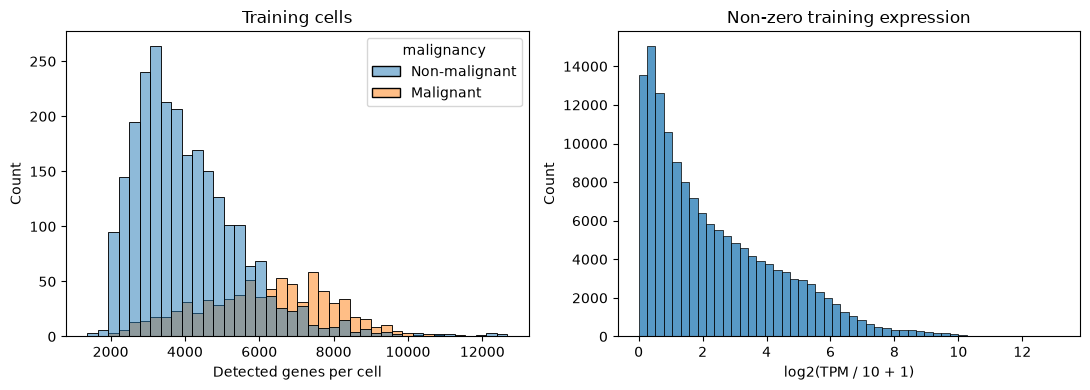

In [8]:
display(train_obs.groupby("malignancy")["n_genes_detected"].describe())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(
    data=train_obs, x="n_genes_detected", hue="malignancy", bins=40, ax=axes[0]
)
axes[0].set(xlabel="Detected genes per cell", title="Training cells")

# Take a regular sample of cells and genes to keep the plot quick
sample_expression = X_train.iloc[::10, ::10].to_numpy().ravel()
sns.histplot(sample_expression[sample_expression > 0], bins=50, ax=axes[1])
axes[1].set(xlabel="log2(TPM / 10 + 1)", title="Non-zero training expression")
plt.tight_layout()
plt.show()

# Modeling

## Prepare the Random Forest Pipeline

We use 200 trees and balanced class weights because we have more non-malignant cells.
We tune tree depth, minimum leaf size, and the number of genes considered at each split.

Our pipeline drops constant genes and fits the forest. During cross-validation, constant genes are
identified separately in each training fold. The validation fold uses that fold's gene selection.
The random forest doesn't need feature scaling.

In [9]:
rf_pipeline = Pipeline(
    [
        ("constant_genes", VarianceThreshold()),
        (
            "rf",
            RandomForestClassifier(
                n_estimators=200,
                class_weight="balanced",
                random_state=RANDOM_STATE,
                n_jobs=-1,
            ),
        ),
    ]
)

## Set Up 5-fold Cross-validation

We split the 15 training tumors into five folds. Each time, we train on four folds and validate on
the remaining fold. Tumors stay together, and we try to keep the class proportions similar.
The four test tumors don't enter cross-validation.

We check the folds before fitting. With only 15 tumors, fold sizes won't be exactly equal.

In [10]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_groups = train_obs["tumor"]

# Use these same folds for every parameter combination
cv_splits = list(cv.split(X_train, y_train, groups=train_groups))
fold_rows = []
for fold, (fit_idx, val_idx) in enumerate(cv_splits, start=1):
    fit_tumors = set(train_groups.iloc[fit_idx])
    val_tumors = sorted(train_groups.iloc[val_idx].unique().tolist())
    assert fit_tumors.isdisjoint(val_tumors)
    assert set(val_tumors).isdisjoint(test_tumors)
    assert y_train.iloc[fit_idx].nunique() == 2 and y_train.iloc[val_idx].nunique() == 2

    fold_rows.append({
        "Fold": fold,
        "Training cells": len(fit_idx),
        "Validation cells": len(val_idx),
        "Validation tumors": val_tumors,
        "Validation malignant fraction": y_train.iloc[val_idx].mean(),
    })

fold_summary = pd.DataFrame(fold_rows).set_index("Fold")
display(fold_summary.round(3))

,Training cells,Validation cells,Validation tumors,Validation malignant fraction
Fold,,,,
1,2584,692,"[74, 75, 78, 82]",0.224
2,2575,701,"[81, 84, 94]",0.224
3,2683,593,"[59, 65, 89]",0.263
4,2723,553,"[71, 80]",0.324
5,2539,737,"[60, 72, 88]",0.171


## Tune the Parameters

We try eight combinations using the same five folds: 40 fits, followed by a refit of the best
pipeline on all 15 training tumors. We select the settings with the highest mean validation
balanced accuracy. We also record ROC AUC and average precision.

We start with a small grid. `max_depth` limits tree depth, `min_samples_leaf` controls how many cells
must remain in a leaf, and `max_features` controls how many genes each split considers.

We use ordinary grouped 5-fold CV for tuning and the separate test tumors for evaluation.
Nested CV would add outer validation folds, with a new tuning search inside each one.
That could give us a broader evaluation of the tuning procedure later.

In [11]:
param_grid = {
    "rf__max_depth": [None, 20],
    "rf__min_samples_leaf": [1, 5],
    "rf__max_features": ["sqrt", "log2"],
}

search = GridSearchCV(
    rf_pipeline,
    param_grid=param_grid,
    cv=cv_splits,
    scoring={
        "balanced_accuracy": "balanced_accuracy",
        "roc_auc": "roc_auc",
        "average_precision": "average_precision",
    },
    refit="balanced_accuracy",
    n_jobs=1,  # The forest already parallelizes trees; run candidates one at a time
    error_score="raise",
    verbose=1,
)
search.fit(X_train, y_train)

# GridSearchCV has already refitted this pipeline on all training tumors
model = search.best_estimator_
selected_genes = X_train.columns[model.named_steps["constant_genes"].get_support()]
print("Best parameters:", search.best_params_)
print(f"Retained {len(selected_genes):,} of {X_train.shape[1]:,} genes.")

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best parameters: {'rf__max_depth': None, 'rf__max_features': 'sqrt', 'rf__min_samples_leaf': 1}
Retained 22,753 of 23,677 genes.


## Check the Cross-validation Results

We compare the parameter combinations and look at each fold for the selected settings.
The standard deviation shows variation across folds; it isn't a confidence interval.

These scores were used to choose the parameters, so the best mean CV score can be optimistic.
We use the held-out tumors for the separate evaluation below.
See [scikit-learn's explanation of nested CV](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html).

In [12]:
search_results = pd.DataFrame(search.cv_results_)
cv_results = search_results[[
    "rank_test_balanced_accuracy",
    "param_rf__max_depth", "param_rf__min_samples_leaf", "param_rf__max_features",
    "mean_test_balanced_accuracy", "std_test_balanced_accuracy",
    "mean_test_roc_auc", "mean_test_average_precision",
]].sort_values("rank_test_balanced_accuracy")
display(cv_results.round(4))

best_result = search_results.iloc[search.best_index_]
cv_fold_metrics = fold_summary.copy()
for metric in ["balanced_accuracy", "roc_auc", "average_precision"]:
    cv_fold_metrics[metric] = [best_result[f"split{fold}_test_{metric}"] for fold in range(5)]
display(cv_fold_metrics.round(4))
print(
    f"Selected settings: mean CV balanced accuracy = {search.best_score_:.4f}, "
    f"fold SD = {best_result['std_test_balanced_accuracy']:.4f}"
)

Selected settings: mean CV balanced accuracy = 0.9855, fold SD = 0.0062


,rank_test_balanced_accuracy,param_rf__max_depth,param_rf__min_samples_leaf,param_rf__max_features,mean_test_balanced_accuracy,std_test_balanced_accuracy,mean_test_roc_auc,mean_test_average_precision
0,1,None,1,sqrt,0.9855,0.0062,0.9964,0.9958
4,1,20,1,sqrt,0.9855,0.0062,0.9964,0.9958
1,3,None,5,sqrt,0.9841,0.0081,0.9962,0.9956
5,3,20,5,sqrt,0.9841,0.0081,0.9962,0.9956
3,5,None,5,log2,0.9663,0.0098,0.9932,0.9848
7,5,20,5,log2,0.9663,0.0098,0.9932,0.9848
2,7,None,1,log2,0.9599,0.0132,0.9945,0.9883
6,8,20,1,log2,0.9599,0.0131,0.9944,0.9883


,Training cells,Validation cells,Validation tumors,Validation malignant fraction,balanced_accuracy,roc_auc,average_precision
Fold,,,,,,,
1,2584,692,"[74, 75, 78, 82]",0.2240,0.9839,0.9889,0.9872
2,2575,701,"[81, 84, 94]",0.2240,0.9832,0.9996,0.9985
3,2683,593,"[59, 65, 89]",0.2631,0.9924,0.9946,0.9951
4,2723,553,"[71, 80]",0.3237,0.9758,0.9991,0.9981
5,2539,737,"[60, 72, 88]",0.1710,0.9921,1.0000,0.9998


# Evaluation

## Predict on the Held-out Tumors

We use the model's default decision threshold (0.5). Malignant is the positive class.
We also fit a majority-class baseline on the training labels so we have a simple comparison.

We choose the forest's settings using CV scores only. We have already seen results on this holdout
during development, so this remains an exploratory evaluation rather than a fresh external test.

In [13]:
y_pred = model.predict(X_test)
malignant_column = np.flatnonzero(model.classes_ == 1)[0]
y_prob = model.predict_proba(X_test)[:, malignant_column]

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
baseline_prob = baseline.predict_proba(X_test)[
    :, np.flatnonzero(baseline.classes_ == 1)[0]
]

## Compare the Scores

Balanced accuracy gives both classes equal weight. Precision tells us how often a predicted malignant
cell is malignant; recall tells us how many malignant cells we find.
ROC AUC and average precision use the predicted probabilities, not the predicted labels.

In [14]:
def compute_metrics(y_true, y_pred, y_prob):
    """Compute binary classification metrics, with malignant as the positive class."""
    return {
        "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Malignant precision": precision_score(y_true, y_pred, zero_division=0),
        "Malignant recall": recall_score(y_true, y_pred, zero_division=0),
        "Malignant F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_true, y_prob),
        "Average precision": average_precision_score(y_true, y_prob),
    }


metrics = pd.DataFrame(
    {
        "Majority baseline": compute_metrics(y_test, baseline_pred, baseline_prob),
        "Random forest": compute_metrics(y_test, y_pred, y_prob),
    }
)
display(metrics.round(3))
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Non-malignant", "Malignant"],
        zero_division=0,
    )
)

               precision    recall  f1-score   support

Non-malignant       1.00      0.99      1.00       753
    Malignant       0.99      1.00      0.99       484

     accuracy                           1.00      1237
    macro avg       1.00      1.00      1.00      1237
 weighted avg       1.00      1.00      1.00      1237



,Majority baseline,Random forest
Balanced accuracy,0.500,0.996
MCC,0.000,0.992
Malignant precision,0.000,0.992
Malignant recall,0.000,0.998
Malignant F1,0.000,0.995
ROC AUC,0.500,1.000
Average precision,0.391,0.999


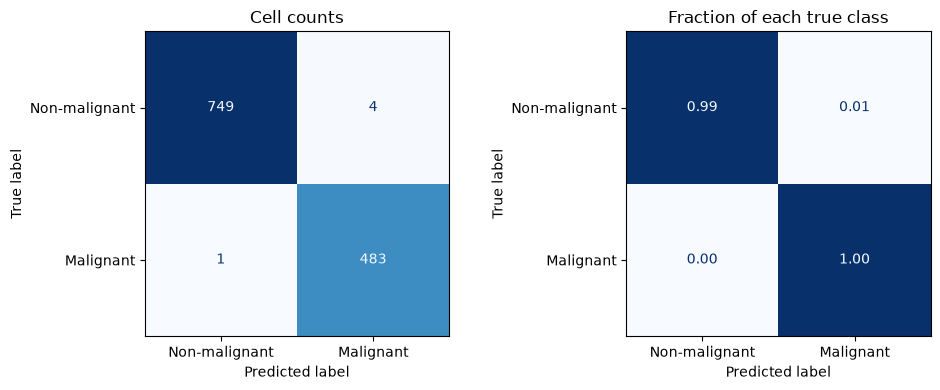

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, normalize, title in zip(
    axes, [None, "true"], ["Cell counts", "Fraction of each true class"]
):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=[0, 1],
        display_labels=["Non-malignant", "Malignant"],
        normalize=normalize,
        cmap="Blues",
        colorbar=False,
        ax=ax,
        values_format="d" if normalize is None else ".2f",
    )
    ax.set_title(title)
plt.tight_layout()
plt.show()

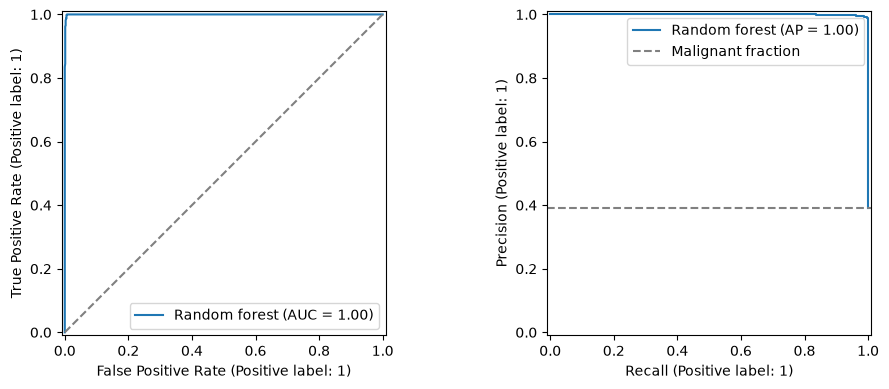

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
RocCurveDisplay.from_predictions(y_test, y_prob, name="Random forest", ax=axes[0])
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
PrecisionRecallDisplay.from_predictions(
    y_test, y_prob, name="Random forest", ax=axes[1]
)
axes[1].axhline(y_test.mean(), linestyle="--", color="gray", label="Malignant fraction")
axes[1].legend()
plt.tight_layout()
plt.show()

## Check Each Test Tumor

The pooled score can hide differences between tumors, especially if one tumor contributes many cells.
We also show results for each held-out tumor. Some tumors have only one class, so their balanced
accuracy and ROC AUC are left empty. Recall or specificity is empty if that class is absent.

In [17]:
test_predictions = test_obs[["tumor", "malignancy", "cell_type_code"]].copy()
test_predictions["true_label"] = y_test
test_predictions["predicted_label"] = y_pred
test_predictions["malignant_probability"] = y_prob

tumor_scores = []
for tumor, cells in test_predictions.groupby("tumor"):
    truth = cells["true_label"]
    pred = cells["predicted_label"]
    has_both_classes = truth.nunique() == 2
    tumor_scores.append(
        {
            "Tumor": tumor,
            "Cells": len(cells),
            "Malignant cells": int((truth == 1).sum()),
            "Balanced accuracy": balanced_accuracy_score(truth, pred)
            if has_both_classes
            else np.nan,
            "Malignant recall": recall_score(truth, pred, zero_division=0)
            if (truth == 1).any()
            else np.nan,
            "Specificity": recall_score(truth, pred, pos_label=0, zero_division=0)
            if (truth == 0).any()
            else np.nan,
            "ROC AUC": roc_auc_score(truth, cells["malignant_probability"])
            if has_both_classes
            else np.nan,
        }
    )

tumor_metrics = pd.DataFrame(tumor_scores).set_index("Tumor")
display(tumor_metrics.round(3))

,Cells,Malignant cells,Balanced accuracy,Malignant recall,Specificity,ROC AUC
Tumor,,,,,,
53,140,16,1.000,1.000,1.00,1.0
58,141,0,NaN,NaN,1.00,NaN
67,95,0,NaN,NaN,1.00,NaN
79,861,468,0.994,0.998,0.99,1.0


## Inspect the Important Genes

We look at the 20 genes with the highest forest importance. These are a starting point for inspection,
not a list of validated malignancy markers. Correlated genes can share importance.

Non-malignant cells here include immune and stromal cells. The model may use lineage differences
to separate them from melanoma cells. These results don't establish a general cancer classifier.

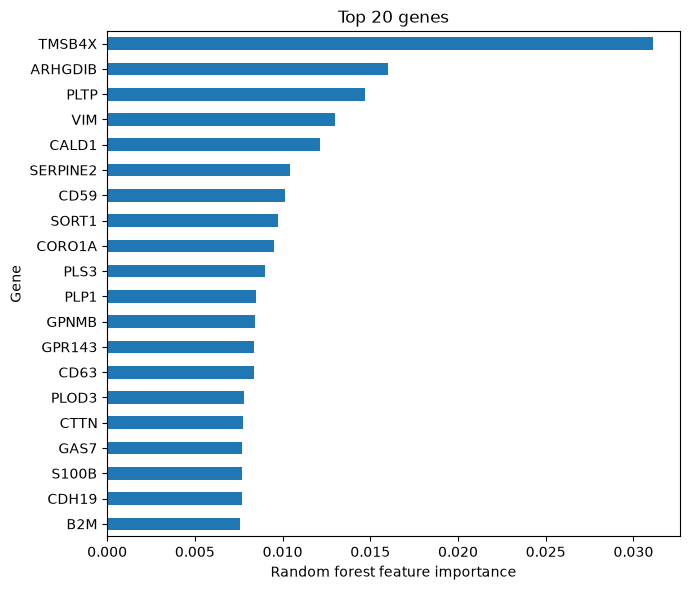

In [18]:
gene_importance = pd.Series(
    model.named_steps["rf"].feature_importances_,
    index=selected_genes,
    name="Importance",
).sort_values(ascending=False)

gene_importance.head(20).sort_values().plot.barh(figsize=(7, 6))
plt.xlabel("Random forest feature importance")
plt.ylabel("Gene")
plt.title("Top 20 genes")
plt.tight_layout()
plt.show()

# Predict the Unresolved Cells

We use the same training-only model for the unresolved cells. We report a predicted label and
malignant probability, but can't score these predictions because we don't have reference labels.
We also record whether each cell comes from a training tumor.

The probabilities aren't calibrated confidence estimates.

In [19]:
unresolved_predictions = unresolved_obs[
    ["tumor", "malignancy", "cell_type_code"]
].copy()
if len(unresolved_predictions):
    X_unresolved = X_all.loc[unresolved_predictions.index]
    unresolved_predictions["predicted_label"] = model.predict(X_unresolved)
    unresolved_predictions["malignant_probability"] = model.predict_proba(X_unresolved)[
        :, malignant_column
    ]
else:
    unresolved_predictions["predicted_label"] = pd.Series(dtype=int)
    unresolved_predictions["malignant_probability"] = pd.Series(dtype=float)

unresolved_predictions["predicted_malignancy"] = unresolved_predictions[
    "predicted_label"
].map({0: "Non-malignant", 1: "Malignant"})
unresolved_predictions["tumor_seen_in_training"] = unresolved_predictions["tumor"].isin(
    train_tumors
)
display(unresolved_predictions.head(10))
display(
    unresolved_predictions["predicted_malignancy"]
    .value_counts()
    .rename("Cells")
    .to_frame()
)

,tumor,malignancy,cell_type_code,predicted_label,malignant_probability,predicted_malignancy,tumor_seen_in_training
Cy81_Bulk_CD45_B11_S119_comb,81,Unresolved,0,1,0.855,Malignant,True
Cy81_Bulk_CD45_D09_S141_comb,81,Unresolved,0,1,0.910,Malignant,True
Cy71_CD45_H07_S571_comb,71,Unresolved,0,0,0.390,Non-malignant,True
Cy81_FNA_CD45_H12_S288_comb,81,Unresolved,1,0,0.165,Non-malignant,True
Cy71_CD45_A04_S484_comb,71,Unresolved,0,1,0.940,Malignant,True
Cy81_Bulk_CD45_C09_S129_comb,81,Unresolved,0,1,0.890,Malignant,True
Cy81_Bulk_CD45_B08_S116_comb,81,Unresolved,0,0,0.385,Non-malignant,True
Cy71_CD45_B04_S496_comb,71,Unresolved,0,1,0.925,Malignant,True
Cy81_FNA_CD45_C01_S217_comb,81,Unresolved,0,0,0.225,Non-malignant,True
Cy71_CD45_H12_S672_comb,71,Unresolved,0,1,0.565,Malignant,True


,Cells
predicted_malignancy,
Malignant,72
Non-malignant,60


# Save the Model and Predictions

We save the fitted pipeline together with its input gene order, original gene symbols, label meanings,
CV settings, best parameters, and package versions. New data must use the same gene names, order, and expression preprocessing.

We keep this model fitted on the training tumors so the saved test predictions remain held-out results.
The full prediction table marks training, test, and unresolved cells. Predictions on training cells
are fitted results and aren't evidence of performance on unseen patients.

We also save the parameter comparison and the five validation-fold scores.

In [20]:
OUTPUT_DIR.mkdir(exist_ok=True)

model_bundle = {
    "pipeline": model,
    "input_genes": X_train.columns.tolist(),
    "gene_symbols": adata.var["gene_symbol"].tolist(),
    "selected_genes": selected_genes.tolist(),
    "labels": {0: "Non-malignant", 1: "Malignant"},
    "expression_transform": "log2(TPM / 10 + 1)",
    "train_tumors": train_tumors,
    "test_tumors": test_tumors,
    "random_state": RANDOM_STATE,
    "cross_validation": {
        "method": "StratifiedGroupKFold",
        "n_splits": 5,
        "selection_metric": "balanced_accuracy",
        "best_params": search.best_params_,
        "mean_validation_balanced_accuracy": search.best_score_,
        "validation_tumors": fold_summary["Validation tumors"].tolist(),
    },
    "parameter_grid": param_grid,
    "dataset": DATA_PATH.name,
    "package_versions": {
        package: version(package)
        for package in [
            "scikit-learn",
            "numpy",
            "pandas",
            "scanpy",
            "anndata",
        ]
    },
}
with (OUTPUT_DIR / "random_forest.pkl").open("wb") as f:
    pickle.dump(model_bundle, f)

cell_predictions = adata.obs.copy()
cell_predictions["true_label"] = cell_predictions["malignancy_code"].map({1: 0, 2: 1})
cell_predictions["split"] = "unresolved"
cell_predictions.loc[X_train.index, "split"] = "train"
cell_predictions.loc[X_test.index, "split"] = "test"
cell_predictions["predicted_label"] = model.predict(X_all)
cell_predictions["predicted_malignancy"] = cell_predictions["predicted_label"].map(
    {0: "Non-malignant", 1: "Malignant"}
)
cell_predictions["malignant_probability"] = model.predict_proba(X_all)[
    :, malignant_column
]
cell_predictions["tumor_seen_in_training"] = cell_predictions["tumor"].isin(
    train_tumors
)

cell_predictions.to_csv(OUTPUT_DIR / "cell_predictions.csv", index_label="cell")
test_predictions.to_csv(OUTPUT_DIR / "test_predictions.csv", index_label="cell")
unresolved_predictions.to_csv(
    OUTPUT_DIR / "unresolved_predictions.csv", index_label="cell"
)
cv_results.to_csv(OUTPUT_DIR / "cv_parameter_results.csv", index=False)
cv_fold_metrics.to_csv(OUTPUT_DIR / "cv_fold_metrics.csv")
metrics.to_csv(OUTPUT_DIR / "test_metrics.csv")
tumor_metrics.to_csv(OUTPUT_DIR / "test_metrics_by_tumor.csv")
gene_importance.to_csv(OUTPUT_DIR / "gene_importance.csv", index_label="gene")
print(f"Saved the model and results to {OUTPUT_DIR.resolve()}")

Saved the model and results to /Users/ioamy269/Documents/GitHub/cellstates/outputs


# Extra Things We Could Try

- **Nested grouped cross-validation:** use outer folds to evaluate the full tuning procedure,
  with a new parameter search inside each outer training set. We could also leave one tumor out at a time.
  Our holdout result still depends on one split, and some test tumors contain only non-malignant cells.
- **Feature selection:** compare all genes with a smaller set selected on training data in each fold.
  We would need to account for this dataset's log2 expression when choosing a highly-variable-gene method.
- **Model comparison and wider tuning:** try logistic regression or expand the forest's parameter grid
  using grouped validation within the training set. We keep the test tumors out of those decisions.
- **Error inspection:** check which non-malignant cell types are mistaken for malignant cells and
  whether performance varies with expression quality or tumor composition.
- **Calibration and thresholds:** use grouped validation to check probabilities and choose a threshold
  if we want to prioritize finding malignant cells or avoiding false positives.
- **External data:** test on another melanoma cohort with compatible gene identifiers and preprocessing.
  A broader malignancy claim would also need appropriate non-malignant lineage controls.
- **Final training:** once we finish choosing and evaluating the approach, fit a separate final model
  on all labeled cells for future predictions. We wouldn't score that model on its training cells.